# CV Project: <br> CNN, RNN, & LSTM

**M. Mahdi Mostafaei** <br>
Team 05 - Pufa

## Environment Setup and GPU Verification

In [1]:
import math
import copy
import random
import sys
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as T
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEV)
if DEV.type == "cuda":
  print("gpu   ", torch.cuda.get_device_name(0))
else:
  print("WARNING: no GPU detected.")

torch 2.10.0+cu126 | device: cuda
gpu    NVIDIA GeForce RTX 3050 6GB Laptop GPU


## Part 1: Convolution and Pooling From Scratch

### 1.1 Convolution Layer `(MyConv)`

In [2]:
class MyConv:
  """A 2D convolution layer written by hand using NumPy."""

  def __init__(self, stride=1, padding=0):
    self.stride = stride
    self.padding = padding

  def forward(self, x, w, b):
    stride, pad = self.stride, self.padding
    N, C, H, W = x.shape
    F_, C_, HH, WW = w.shape
    assert C == C_, "filter channel count must match the input"

    H_out = int(np.floor((H + 2 * pad - HH) / stride) + 1)
    W_out = int(np.floor((W + 2 * pad - WW) / stride) + 1)

    x_pad = np.pad(
        x, ((0, 0), (0, 0), (pad, pad), (pad, pad)), mode="constant"
    )
    out = np.zeros((N, F_, H_out, W_out), dtype=x.dtype)

    for n in range(N):
      for f in range(F_):
        for i in range(H_out):
          for j in range(W_out):
            hs, ws = i * stride, j * stride
            window = x_pad[n, :, hs : hs + HH, ws : ws + WW]
            out[n, f, i, j] = np.sum(window * w[f]) + b[f]

    self.cache = (x, w, b, x_pad)
    return out

  def backward(self, dout):
    x, w, b, x_pad = self.cache
    stride, pad = self.stride, self.padding
    N, C, H, W = x.shape
    F_, _, HH, WW = w.shape
    _, _, H_out, W_out = dout.shape

    dw = np.zeros_like(w)
    db = np.zeros_like(b)
    dx_pad = np.zeros_like(x_pad)

    for n in range(N):
      for f in range(F_):
        for i in range(H_out):
          for j in range(W_out):
            hs, ws = i * stride, j * stride
            grad_val = dout[n, f, i, j]
            db[f] += grad_val
            dw[f] += x_pad[n, :, hs : hs + HH, ws : ws + WW] * grad_val
            dx_pad[n, :, hs : hs + HH, ws : ws + WW] += w[f] * grad_val

    dx = dx_pad[:, :, pad : pad + H, pad : pad + W]
    self.dx, self.dw, self.db = dx, dw, db
    return dx, dw, db

Gradient Checking Utilities and Tests

In [3]:
def rel_error(a, b):
  return np.max(np.abs(a - b) / np.maximum(1e-8, np.abs(a) + np.abs(b)))


def numeric_grad(f, x, df, h=1e-5):
  g = np.zeros_like(x)
  it = np.nditer(x, flags=["multi_index"], op_flags=["readwrite"])
  while not it.finished:
    ix = it.multi_index
    old = x[ix]
    x[ix] = old + h
    pos = f(x).copy()
    x[ix] = old - h
    neg = f(x).copy()
    x[ix] = old
    g[ix] = np.sum((pos - neg) * df) / (2 * h)
    it.iternext()
  return g


# Forward check
x = np.linspace(-0.1, 0.5, num=2 * 3 * 4 * 4).reshape(2, 3, 4, 4)
w = np.linspace(-0.2, 0.3, num=3 * 3 * 4 * 4).reshape(3, 3, 4, 4)
b = np.linspace(-0.1, 0.2, num=3)

out = MyConv(stride=2, padding=1).forward(x, w, b)
expected = np.array([
    [
        [[-0.08759809, -0.10987781], [-0.18387192, -0.2109216]],
        [[0.21027089, 0.21661097], [0.22847626, 0.23004637]],
        [[0.50813986, 0.54309974], [0.64082444, 0.67101435]],
    ],
    [
        [[-0.98053589, -1.03143541], [-1.19128892, -1.24695841]],
        [[0.69108355, 0.66880383], [0.59480972, 0.56776003]],
        [[2.36270298, 2.36904306], [2.38090835, 2.38247847]],
    ],
])
err = rel_error(out, expected)
print(f"forward relative error: {err:.3e}")
assert err < 1e-7, "forward pass is wrong"
print("forward OK")

# Backward check
rng = np.random.default_rng(1)
x = rng.standard_normal((4, 3, 5, 5))
w = rng.standard_normal((2, 3, 3, 3))
b = rng.standard_normal(2)
dout = rng.standard_normal((4, 2, 5, 5))

conv = MyConv(stride=1, padding=1)
dx_n = numeric_grad(lambda t: conv.forward(t, w, b), x, dout)
dw_n = numeric_grad(lambda t: conv.forward(x, t, b), w, dout)
db_n = numeric_grad(lambda t: conv.forward(x, w, t), b, dout)

conv.forward(x, w, b)
dx, dw, db = conv.backward(dout)

for name, a, n in [("dx", dx, dx_n), ("dw", dw, dw_n), ("db", db, db_n)]:
  e = rel_error(a, n)
  print(f"{name} relative error: {e:.3e}")
  assert e < 1e-7, f"{name} is wrong"
print("backward OK")

forward relative error: 2.212e-08
forward OK
dx relative error: 1.792e-09
dw relative error: 3.346e-10
db relative error: 3.494e-12
backward OK


### 1.2 Max Pooling `(MyMaxPool)`

In [4]:
class MyMaxPool:
  """Max pooling written by hand with exact single-route tie-breaking."""

  def __init__(self, size=2, stride=2):
    self.size, self.stride = size, stride

  def forward(self, x):
    k, s = self.size, self.stride
    N, C, H, W = x.shape
    H_out = int(np.floor((H - k) / s) + 1)
    W_out = int(np.floor((W - k) / s) + 1)
    out = np.zeros((N, C, H_out, W_out), dtype=x.dtype)

    for n in range(N):
      for c in range(C):
        for i in range(H_out):
          for j in range(W_out):
            hs, ws = i * s, j * s
            window = x[n, c, hs : hs + k, ws : ws + k]
            out[n, c, i, j] = np.max(window)

    self.cache = x
    return out

  def backward(self, dout):
    x = self.cache
    k, s = self.size, self.stride
    dx = np.zeros_like(x)
    N, C, H_out, W_out = dout.shape

    for n in range(N):
      for c in range(C):
        for i in range(H_out):
          for j in range(W_out):
            hs, ws = i * s, j * s
            window = x[n, c, hs : hs + k, ws : ws + k]
            max_idx = np.argmax(window)
            r, cl = np.unravel_index(max_idx, window.shape)
            dx[n, c, hs + r, ws + cl] += dout[n, c, i, j]

    self.dx = dx
    return dx


# Pooling checks
rng = np.random.default_rng(2)
x = rng.standard_normal((3, 2, 6, 6))
pool = MyMaxPool(size=2, stride=2)

out = pool.forward(x)
assert out.shape == (3, 2, 3, 3), f"wrong output shape: {out.shape}"
ref = x.reshape(3, 2, 3, 2, 3, 2).max(axis=(3, 5))
assert rel_error(out, ref) < 1e-12, "pooling forward is wrong"
print("pooling forward OK")

dout = rng.standard_normal(out.shape)
dx_n = numeric_grad(lambda t: pool.forward(t), x, dout)
pool.forward(x)
dx = pool.backward(dout)
e = rel_error(dx, dx_n)
print(f"dx relative error: {e:.3e}")
assert e < 1e-7, "pooling backward is wrong"
assert (dx != 0).sum() == out.size, (
    "exactly one input per window should receive gradient"
)
print("pooling backward OK")

pooling forward OK
dx relative error: 3.276e-12
pooling backward OK


### 1.3 Handmade Kernels

input batch: (2, 3, 256, 256)
output: (2, 4, 256, 256)


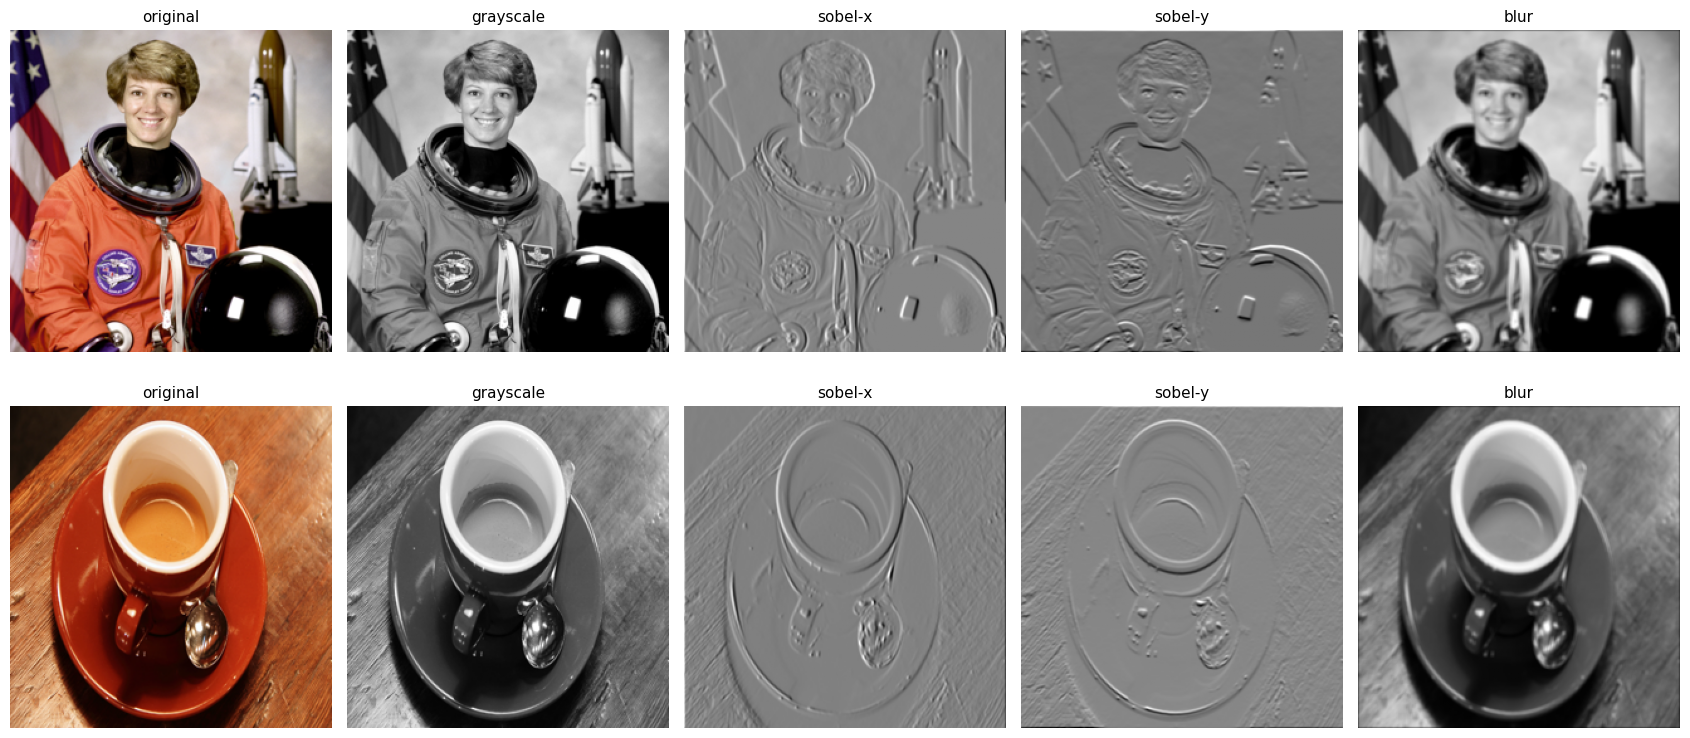

In [7]:
from skimage.data import astronaut, coffee

imgs = [astronaut(), coffee()]


SZ = 256
x_img = np.stack([
    np.array(Image.fromarray(im).resize((SZ, SZ))).transpose(2, 0, 1)
    for im in imgs
]).astype(np.float64)
print("input batch:", x_img.shape)

w = np.zeros((4, 3, 3, 3))

# Filter 0: Grayscale (0.3 R, 0.6 G, 0.1 B at center tap)
w[0, 0, 1, 1] = 0.3
w[0, 1, 1, 1] = 0.6
w[0, 2, 1, 1] = 0.1

# Filter 1: Sobel-x
sobel_x = np.array([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]])
for c in range(3):
  w[1, c] = sobel_x / 3.0

# Filter 2: Sobel-y
sobel_y = np.array([[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]])
for c in range(3):
  w[2, c] = sobel_y / 3.0

# Filter 3: Box blur
box_blur = np.ones((3, 3)) / 9.0
for c in range(3):
  w[3, c] = box_blur / 3.0

b = np.zeros(4)
out = MyConv(stride=1, padding=1).forward(x_img, w, b)
print("output:", out.shape)
assert out.shape == (2, 4, SZ, SZ)

titles = ["original", "grayscale", "sobel-x", "sobel-y", "blur"]
fig, ax = plt.subplots(2, 5, figsize=(17, 8))
for n in range(2):
  ax[n, 0].imshow(x_img[n].transpose(1, 2, 0).astype(np.uint8))
  for f in range(4):
    ax[n, f + 1].imshow(out[n, f], cmap="gray")
  for k in range(5):
    ax[n, k].set_title(titles[k], fontsize=11)
    ax[n, k].axis("off")
plt.tight_layout()
plt.show()

## Part 2: Depth Experiment (Plain vs. Residual)

### 2.1 Dataset Setup and Network Construction

In [3]:
tf_train = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)),
])
tf_test = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)),
])

full_tr = torchvision.datasets.CIFAR10(
    "./data", train=True, download=True, transform=tf_train
)
full_te = torchvision.datasets.CIFAR10(
    "./data", train=False, download=True, transform=tf_test
)

g = torch.Generator().manual_seed(0)
idx = torch.randperm(len(full_tr), generator=g)[:20000]
train_ds = Subset(full_tr, idx.tolist())

train_ld = DataLoader(
    train_ds,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True,
)
test_ld = DataLoader(
    full_te, batch_size=512, shuffle=False, num_workers=2, pin_memory=True
)
print(f"train {len(train_ds)}  test {len(full_te)}")


class Block(nn.Module):

  def __init__(self, c_in, c_out, stride, residual):
    super().__init__()
    self.residual = residual

    self.conv1 = nn.Conv2d(
        c_in, c_out, kernel_size=3, stride=stride, padding=1, bias=False
    )
    self.bn1 = nn.BatchNorm2d(c_out)
    self.conv2 = nn.Conv2d(
        c_out, c_out, kernel_size=3, stride=1, padding=1, bias=False
    )
    self.bn2 = nn.BatchNorm2d(c_out)

    self.short = nn.Identity()
    if residual and (stride != 1 or c_in != c_out):
      self.short = nn.Sequential(
          nn.Conv2d(c_in, c_out, kernel_size=1, stride=stride, bias=False),
          nn.BatchNorm2d(c_out),
      )

  def forward(self, x):
    out = F.relu(self.bn1(self.conv1(x)))
    out = self.bn2(self.conv2(out))
    if self.residual:
      out = out + self.short(x)
    return F.relu(out)


class Net(nn.Module):

  def __init__(self, n=1, residual=False, num_classes=10):
    super().__init__()
    self.stem = nn.Sequential(
        nn.Conv2d(3, 32, 3, 1, 1, bias=False),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
    )
    layers, c_in = [], 32
    for c_out, stride in [(32, 1), (64, 2), (128, 2)]:
      for k in range(n):
        layers.append(Block(c_in, c_out, stride if k == 0 else 1, residual))
        c_in = c_out
    self.body = nn.Sequential(*layers)
    self.head = nn.Linear(128, num_classes)

  def forward(self, x):
    x = self.body(self.stem(x))
    return self.head(F.adaptive_avg_pool2d(x, 1).flatten(1))


def depth_of(n):
  return 2 * 3 * n + 2


# Shape & projection checks
for n in (1, 8):
  for res in (False, True):
    m = Net(n=n, residual=res)
    y = m(torch.randn(2, 3, 32, 32))
    assert y.shape == (2, 10), f"bad output shape for n={n}, residual={res}"
print("shapes OK")

m = Net(n=8, residual=True)
proj = [b for b in m.body if not isinstance(b.short, nn.Identity)]
assert len(proj) == 2, f"expected exactly 2 projection shortcuts, got {len(proj)}"
print(f"depth n=1 -> {depth_of(1)} layers,  n=8 -> {depth_of(8)} layers")
print(f"params n=8 residual: {sum(p.numel() for p in m.parameters()):,}")
print("projection shortcuts OK")

train 20000  test 10000
shapes OK
depth n=1 -> 8 layers,  n=8 -> 50 layers
params n=8 residual: 3,024,426
projection shortcuts OK


### 2.2 Model Training and Comparison


=== depth8-plain ===
  [depth8-plain] epoch  1/10  train_loss 1.7839  test_acc 35.51%
  [depth8-plain] epoch  2/10  train_loss 1.4656  test_acc 40.91%
  [depth8-plain] epoch  3/10  train_loss 1.2291  test_acc 53.49%
  [depth8-plain] epoch  4/10  train_loss 1.0800  test_acc 57.47%
  [depth8-plain] epoch  5/10  train_loss 0.9776  test_acc 59.99%
  [depth8-plain] epoch  6/10  train_loss 0.8849  test_acc 61.75%
  [depth8-plain] epoch  7/10  train_loss 0.7988  test_acc 69.85%
  [depth8-plain] epoch  8/10  train_loss 0.7332  test_acc 72.68%
  [depth8-plain] epoch  9/10  train_loss 0.6733  test_acc 74.36%
  [depth8-plain] epoch 10/10  train_loss 0.6310  test_acc 76.11%
  [depth8-plain] done in 183s

=== depth8-res ===
  [depth8-res] epoch  1/10  train_loss 1.7928  test_acc 41.10%
  [depth8-res] epoch  2/10  train_loss 1.4658  test_acc 46.51%
  [depth8-res] epoch  3/10  train_loss 1.2523  test_acc 45.20%
  [depth8-res] epoch  4/10  train_loss 1.0919  test_acc 59.33%
  [depth8-res] epoch  5/10

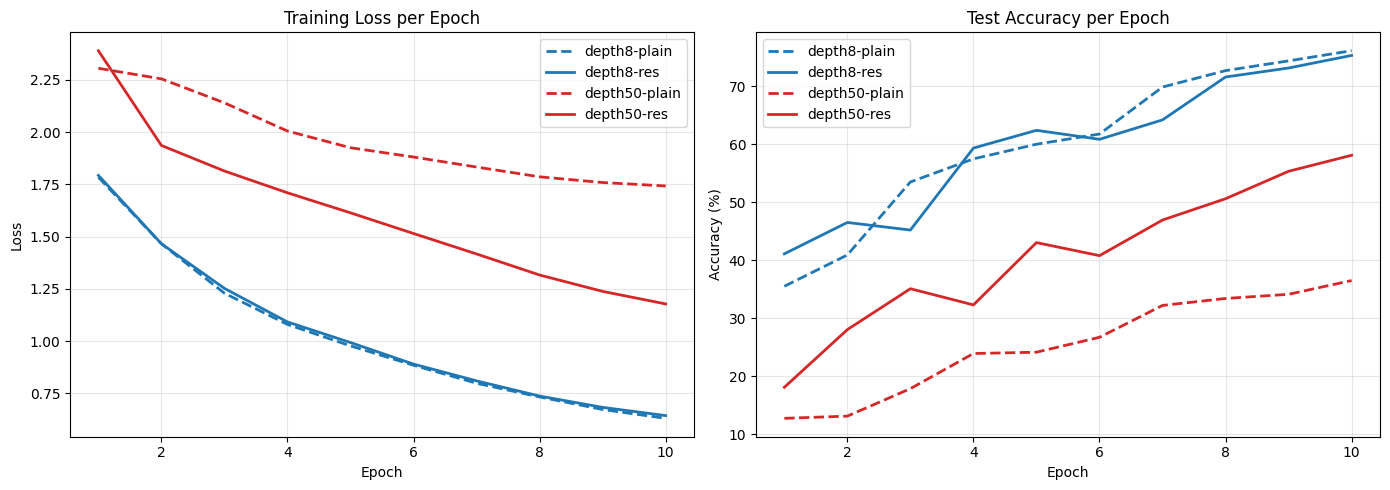

run                     final train loss   final test acc
depth8-plain                      0.6310           76.11%
depth8-res                        0.6441           75.30%
depth50-plain                     1.7421           36.50%
depth50-res                       1.1781           58.09%


In [13]:
def train(model, epochs=10, lr=0.1, tag=""):
  model = model.to(DEV)
  opt = torch.optim.SGD(
      model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4
  )
  sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
  lossf = nn.CrossEntropyLoss()
  hist = {"train_loss": [], "test_acc": []}
  t0 = time.time()

  for ep in range(epochs):
    model.train()
    tot = nb = 0
    for xb, yb in train_ld:
      xb, yb = xb.to(DEV, non_blocking=True), yb.to(DEV, non_blocking=True)
      opt.zero_grad(set_to_none=True)
      loss = lossf(model(xb), yb)
      loss.backward()
      opt.step()
      tot += loss.item()
      nb += 1
    sched.step()
    hist["train_loss"].append(tot / nb)

    model.eval()
    ok = tot_n = 0
    with torch.no_grad():
      for xb, yb in test_ld:
        xb, yb = xb.to(DEV), yb.to(DEV)
        ok += (model(xb).argmax(1) == yb).sum().item()
        tot_n += yb.numel()
    hist["test_acc"].append(ok / tot_n)
    print(
        f"  [{tag}] epoch {ep+1:>2}/{epochs}  train_loss"
        f" {hist['train_loss'][-1]:.4f}  test_acc"
        f" {hist['test_acc'][-1]*100:5.2f}%"
    )

  print(f"  [{tag}] done in {time.time()-t0:.0f}s")
  return hist


results = {}
for n in (1, 8):
  for res in (False, True):
    name = f"depth{depth_of(n)}-{'res' if res else 'plain'}"
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    results[name] = train(Net(n=n, residual=res), epochs=10, tag=name)

# Plotting the 4 runs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
styles = {
    "depth8-plain": {"color": "#1f77b4", "ls": "--", "label": "depth8-plain"},
    "depth8-res": {"color": "#1f77b4", "ls": "-", "label": "depth8-res"},
    "depth50-plain": {
        "color": "#d62728",
        "ls": "--",
        "label": "depth50-plain",
    },
    "depth50-res": {"color": "#d62728", "ls": "-", "label": "depth50-res"},
}

for name, hist in results.items():
  epochs = range(1, len(hist["train_loss"]) + 1)
  cfg = styles[name]
  axes[0].plot(
      epochs,
      hist["train_loss"],
      label=cfg["label"],
      color=cfg["color"],
      linestyle=cfg["ls"],
      lw=2,
  )
  axes[1].plot(
      epochs,
      [a * 100 for a in hist["test_acc"]],
      label=cfg["label"],
      color=cfg["color"],
      linestyle=cfg["ls"],
      lw=2,
  )

axes[0].set_title("Training Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Test Accuracy per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"{'run':<22}{'final train loss':>18}{'final test acc':>17}")
for k, h in results.items():
  print(f"{k:<22}{h['train_loss'][-1]:>18.4f}{h['test_acc'][-1]*100:>16.2f}%")

### 2.3 Layer-wise Gradient Norms

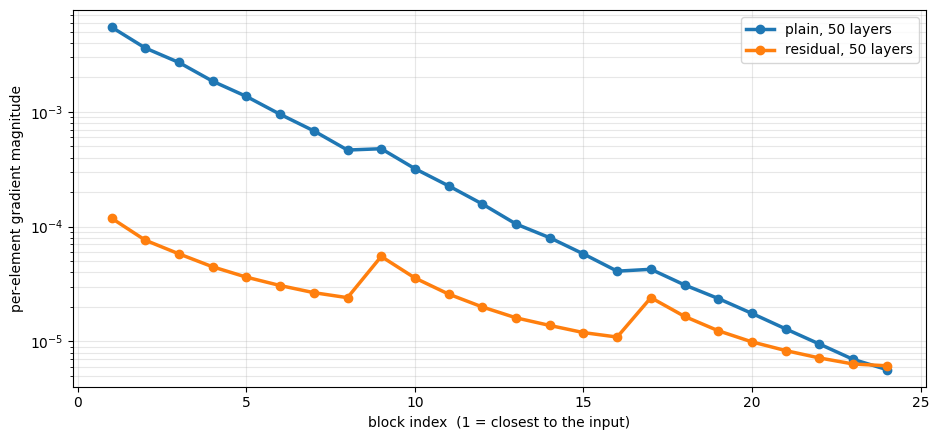

plain    spread across depth: 9.63e+02   (3.0 orders of magnitude)
residual spread across depth: 1.93e+01   (1.3 orders of magnitude)


In [14]:
def block_grad_norms(model, xb, yb):
  """Per-element RMS gradient at the output of every block, ordered input -> output."""
  model = model.to(DEV).train()
  norms = []

  x = model.stem(xb)
  block_outputs = []
  for block in model.body:
    x = block(x)
    x.retain_grad()
    block_outputs.append(x)

  out = model.head(F.adaptive_avg_pool2d(x, 1).flatten(1))
  loss = F.cross_entropy(out, yb)
  loss.backward()

  for a in block_outputs:
    norms.append((a.grad.norm() / (a.grad.numel() ** 0.5)).item())
  return norms


xb, yb = next(iter(train_ld))
xb, yb = xb.to(DEV), yb.to(DEV)

torch.manual_seed(SEED)
g_plain = block_grad_norms(Net(n=8, residual=False), xb, yb)
torch.manual_seed(SEED)
g_res = block_grad_norms(Net(n=8, residual=True), xb, yb)

NB = 24
assert len(g_plain) == NB and len(g_res) == NB

plt.figure(figsize=(9.5, 4.5))
plt.semilogy(range(1, NB + 1), g_plain, "o-", lw=2.5, label="plain, 50 layers")
plt.semilogy(
    range(1, NB + 1), g_res, "o-", lw=2.5, label="residual, 50 layers"
)
plt.xlabel("block index  (1 = closest to the input)")
plt.ylabel("per-element gradient magnitude")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

sp = max(g_plain) / min(g_plain)
sr = max(g_res) / min(g_res)
print(
    f"plain    spread across depth: {sp:.2e}   ({math.log10(sp):.1f} orders of"
    " magnitude)"
)
print(
    f"residual spread across depth: {sr:.2e}   ({math.log10(sr):.1f} orders of"
    " magnitude)"
)

## Part 3: Memory Experiment (RNN vs. LSTM)

### 3.1 Sequential Dataset and Recurrent Cells

In [2]:
mnist_tr = torchvision.datasets.MNIST(
    "./data", train=True, download=True, transform=T.ToTensor()
)
mnist_te = torchvision.datasets.MNIST(
    "./data", train=False, download=True, transform=T.ToTensor()
)


def _pack(ds, n):
  xs = torch.stack([ds[i][0] for i in range(n)])
  ys = torch.tensor([ds[i][1] for i in range(n)])
  return xs, ys


TR_X, TR_Y = _pack(mnist_tr, 20000)
TE_X, TE_Y = _pack(mnist_te, 4000)


class SeqTask(torch.utils.data.Dataset):

  def __init__(self, X, Y, T_len, size, seed=0):
    self.X, self.Y, self.T, self.size = X, Y, T_len, size
    self.g = np.random.default_rng(seed)
    self.idx = self.g.integers(0, len(X), size=(size, T_len))

  def __len__(self):
    return self.size

  def __getitem__(self, i):
    ids = self.idx[i]
    seq = self.X[ids]
    label = (self.Y[ids[0]].item() + self.Y[ids[-1]].item()) % 10
    return seq, label


def seq_loaders(T_len, bs=64, n_tr=12000, n_te=2000):
  tr = SeqTask(TR_X, TR_Y, T_len, n_tr, seed=1)
  te = SeqTask(TE_X, TE_Y, T_len, n_te, seed=2)
  return (
      DataLoader(
          tr, batch_size=bs, shuffle=True, num_workers=0, drop_last=True
      ),
      DataLoader(te, batch_size=256, shuffle=False, num_workers=0),
  )


class Encoder(nn.Module):

  def __init__(self, out_dim=64):
    super().__init__()
    self.net = nn.Sequential(
        nn.Conv2d(1, 16, 3, 2, 1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.Conv2d(16, 32, 3, 2, 1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.AdaptiveAvgPool2d(1),
        nn.Flatten(),
        nn.Linear(32, out_dim),
        # nn.ReLU(),
    )

  def forward(self, x):
    return self.net(x)


class MyRNNCell(nn.Module):

  def __init__(self, in_dim, hid):
    super().__init__()
    self.Wx = nn.Linear(in_dim, hid)
    self.Wh = nn.Linear(hid, hid, bias=False)
    self.hid = hid
    nn.init.orthogonal_(self.Wh.weight)   # <-- add this


  def forward(self, x, h):
    return torch.tanh(self.Wx(x) + self.Wh(h))


class MyLSTMCell(nn.Module):
  def __init__(self, in_dim, hid):
    super().__init__()
    self.hid = hid
    self.gates = nn.Linear(in_dim + hid, 4 * hid)
    with torch.no_grad():
      # Order: forget (f), input (i), candidate (g), output (o)
      self.gates.bias.fill_(0.0)       # <--- ADD THIS LINE FIRST
      self.gates.bias[:hid].fill_(3.0)

  def forward(self, x, h, c):
    xh = torch.cat([x, h], dim=1)
    gates = self.gates(xh)
    f, i, g, o = gates.chunk(4, dim=1)
    f = torch.sigmoid(f)
    i = torch.sigmoid(i)
    g = torch.tanh(g)
    o = torch.sigmoid(o)
    c_next = f * c + i * g
    h_next = o * torch.tanh(c_next)
    return h_next, c_next


class SeqModel(nn.Module):

  def __init__(self, cell_type="rnn", hid=128, enc_dim=64):
    super().__init__()
    self.enc = Encoder(enc_dim)
    self.cell_type = cell_type
    self.hid = hid
    self.cell = (
        MyRNNCell(enc_dim, hid)
        if cell_type == "rnn"
        else MyLSTMCell(enc_dim, hid)
    )
    self.head = nn.Linear(hid, 10)

  def forward(self, seq, keep_states=False):
    B, Tn = seq.shape[0], seq.shape[1]
    feats = self.enc(seq.reshape(B * Tn, *seq.shape[2:])).reshape(B, Tn, -1)

    h = torch.zeros(B, self.hid, device=seq.device)
    c = torch.zeros(B, self.hid, device=seq.device)
    states = []

    for t in range(Tn):
      xt = feats[:, t]
      if self.cell_type == "rnn":
        h = self.cell(xt, h)
      else:
        h, c = self.cell(xt, h, c)
      if keep_states:
        h.retain_grad()
        states.append(h)

    out = self.head(h)
    return (out, states) if keep_states else out


# Verify LSTM unit
cell = MyLSTMCell(8, 16)
h0, c0 = torch.zeros(5, 16), torch.zeros(5, 16)
h1, c1 = cell(torch.randn(5, 8), h0, c0)
assert h1.shape == (5, 16) and c1.shape == (5, 16)
n_par = sum(p.numel() for p in cell.parameters())
assert n_par == 4 * 16 * (8 + 16) + 4 * 16
b = cell.gates.bias.detach()
assert (b.abs() > 0.5).sum() >= 16
h, c = cell(torch.zeros(5, 8), h0, c0)
assert c.abs().max() < 1e-6
print(f"LSTM cell OK ({n_par:,} parameters)")

LSTM cell OK (1,600 parameters)


### 3.2 Sequential Training and Forgetting

[phase1] epoch  1/15  test_acc 46.40%
[phase1] epoch  2/15  test_acc 60.68%
[phase1] epoch  3/15  test_acc 49.12%
[phase1] epoch  4/15  test_acc 74.38%
[phase1] epoch  5/15  test_acc 80.58%
[phase1] epoch  6/15  test_acc 79.03%
[phase1] epoch  7/15  test_acc 82.67%
[phase1] epoch  8/15  test_acc 82.08%
[phase1] epoch  9/15  test_acc 81.85%
[phase1] epoch 10/15  test_acc 89.20%
[phase1] epoch 11/15  test_acc 69.30%
[phase1] epoch 12/15  test_acc 86.08%
[phase1] epoch 13/15  test_acc 86.90%
[phase1] epoch 14/15  test_acc 83.62%
[phase1] epoch 15/15  test_acc 87.58%

=== rnn-T4 ===
  [rnn-T4] frozen ep 1/4  acc 20.95%
  [rnn-T4] frozen ep 2/4  acc 31.15%
  [rnn-T4] frozen ep 3/4  acc 51.25%
  [rnn-T4] frozen ep 4/4  acc 59.40%
  [rnn-T4] ft     ep 1/20  loss 0.9251  acc 68.85%
  [rnn-T4] ft     ep 2/20  loss 0.7946  acc 64.50%
  [rnn-T4] ft     ep 3/20  loss 0.7067  acc 71.75%
  [rnn-T4] ft     ep 4/20  loss 0.6426  acc 70.85%
  [rnn-T4] ft     ep 5/20  loss 0.5837  acc 72.60%
  [rnn-T4] 

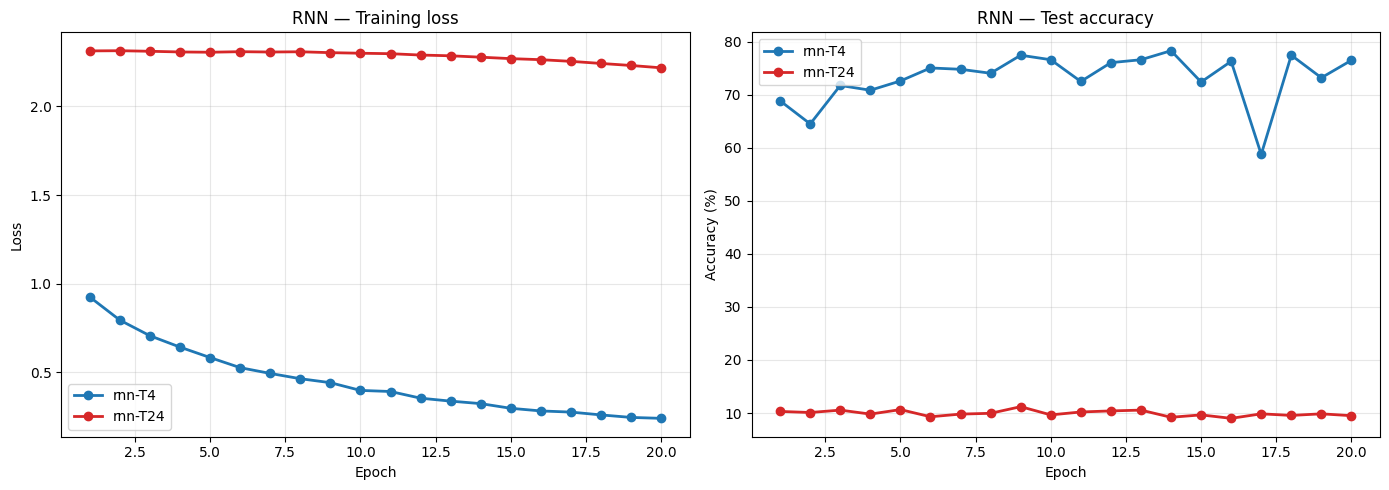

run           final loss   test acc
rnn-T4            0.2409     76.50%
rnn-T24           2.2181      9.50%


In [5]:
# =========================================================
# PHASE 1 — pretrain encoder on single-frame MNIST
# =========================================================
import copy

class FrameDS(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X, self.Y = X, Y
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], int(self.Y[i])

frame_tr = DataLoader(FrameDS(TR_X, TR_Y), batch_size=128,
                      shuffle=True, num_workers=0, pin_memory=True, drop_last=True)
frame_te = DataLoader(FrameDS(TE_X, TE_Y), batch_size=512,
                      shuffle=False, num_workers=0, pin_memory=True)

class EncClf(nn.Module):
    def __init__(self, enc_dim=64):
        super().__init__()
        self.enc = Encoder(enc_dim)
        self.head = nn.Linear(enc_dim, 10)
    def forward(self, x):
        return self.head(self.enc(x))

torch.manual_seed(SEED)
probe = EncClf().to(DEV)
opt = torch.optim.Adam(probe.parameters(), lr=2e-3)
lossf = nn.CrossEntropyLoss()
EPOCHS_P1 = 15

for ep in range(EPOCHS_P1):
    probe.train()
    for xb, yb in frame_tr:
        xb, yb = xb.to(DEV, non_blocking=True), yb.to(DEV, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        loss = lossf(probe(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(probe.parameters(), 5.0)
        opt.step()
    probe.eval(); ok = n = 0
    with torch.no_grad():
        for xb, yb in frame_te:
            xb, yb = xb.to(DEV), yb.to(DEV)
            ok += (probe(xb).argmax(1) == yb).sum().item(); n += yb.numel()
    print(f"[phase1] epoch {ep+1:2d}/{EPOCHS_P1}  test_acc {ok/n*100:5.2f}%")

pretrained_enc_state = copy.deepcopy(probe.enc.state_dict())


# =========================================================
# PHASE 2 — two-phase sequence training
# =========================================================
def train_seq_2phase(model, T_len, epochs_frozen=4, epochs_ft=20, lr=1e-3, tag=""):
    tr, te = seq_loaders(T_len)
    model = model.to(DEV)
    lossf = nn.CrossEntropyLoss()

    # --- 2a: freeze encoder, train only recurrence + head ---
    for p in model.enc.parameters():
        p.requires_grad = False
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=3e-3)
    for ep in range(epochs_frozen):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(DEV, non_blocking=True), yb.to(DEV, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss = lossf(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)   # <-- fixed
            opt.step()
        model.eval(); ok = n = 0
        with torch.no_grad():
            for xb, yb in te:
                xb, yb = xb.to(DEV), yb.to(DEV)
                ok += (model(xb).argmax(1) == yb).sum().item(); n += yb.numel()
        print(f"  [{tag}] frozen ep {ep+1}/{epochs_frozen}  acc {ok/n*100:5.2f}%")

    # --- 2b: unfreeze, fine-tune end-to-end ---
    for p in model.enc.parameters():
        p.requires_grad = True
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "test_acc": []}
    for ep in range(epochs_ft):
        model.train(); tot = nb = 0
        for xb, yb in tr:
            xb, yb = xb.to(DEV, non_blocking=True), yb.to(DEV, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss = lossf(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)   # <-- added
            opt.step()
            tot += loss.item(); nb += 1
        hist["train_loss"].append(tot / nb)
        model.eval(); ok = n = 0
        with torch.no_grad():
            for xb, yb in te:
                xb, yb = xb.to(DEV), yb.to(DEV)
                ok += (model(xb).argmax(1) == yb).sum().item(); n += yb.numel()
        hist["test_acc"].append(ok / n)
        print(f"  [{tag}] ft     ep {ep+1}/{epochs_ft}  loss {hist['train_loss'][-1]:.4f}"
              f"  acc {ok/n*100:5.2f}%")
    return hist


# =========================================================
# Train RNN at T=4 and T=24
# =========================================================
seq_results = {}
trained_models = {}
for T_len in (4, 24):
    name = f"rnn-T{T_len}"
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    m = SeqModel("rnn")
    m.enc.load_state_dict(pretrained_enc_state)
    seq_results[name] = train_seq_2phase(
        m, T_len, epochs_frozen=4, epochs_ft=20, lr=1e-3, tag=name)
    trained_models[name] = m


# =========================================================
# Plot RNN loss & accuracy
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"rnn-T4": "#1f77b4", "rnn-T24": "#d62728"}
for name in ("rnn-T4", "rnn-T24"):
    h = seq_results[name]
    ep = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], "o-", color=colors[name], lw=2, label=name)
    axes[1].plot(ep, [a * 100 for a in h["test_acc"]], "o-",
                 color=colors[name], lw=2, label=name)
axes[0].set_title("RNN — Training loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[1].set_title("RNN — Test accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")
for ax in axes: ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'run':<12}{'final loss':>12}{'test acc':>11}")
for k in ("rnn-T4", "rnn-T24"):
    h = seq_results[k]
    print(f"{k:<12}{h['train_loss'][-1]:>12.4f}{h['test_acc'][-1]*100:>10.2f}%")

### 3.3 Timestep Gradient Tracking (RNN)


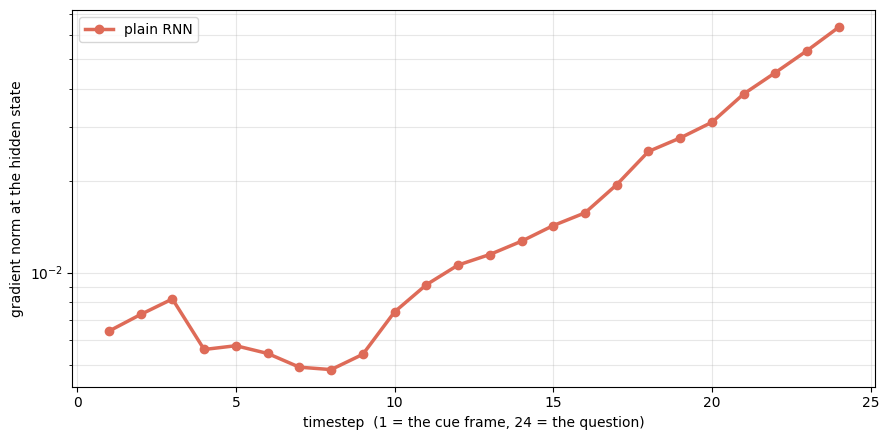

gradient at t=1 is 9.88e+00 times smaller than at t=24


In [6]:
# =========================================================
# Gradient at each timestep, on the trained T=24 RNN
# =========================================================
def timestep_grad_norms(model, T_len, batch=64):
    tr, _ = seq_loaders(T_len, bs=batch)
    xb, yb = next(iter(tr))
    xb, yb = xb.to(DEV), yb.to(DEV)
    model = model.to(DEV).train()
    out, states = model(xb, keep_states=True)
    loss = F.cross_entropy(out, yb)
    loss.backward()
    return [s.grad.norm().item() for s in states]


gn_rnn = timestep_grad_norms(trained_models["rnn-T24"], 24)
assert len(gn_rnn) == 24

plt.figure(figsize=(9, 4.5))
plt.semilogy(range(1, 25), gn_rnn, "o-", lw=2.5, color="#DE6B58", label="plain RNN")
plt.xlabel("timestep  (1 = the cue frame, 24 = the question)")
plt.ylabel("gradient norm at the hidden state")
plt.grid(alpha=0.3, which="both"); plt.legend(); plt.tight_layout(); plt.show()

print(f"gradient at t=1 is {gn_rnn[-1] / max(gn_rnn[0], 1e-30):.2e} times "
      f"smaller than at t=24")

### 3.4 LSTM Training & Gradient Comparison


=== lstm-T4 ===
  [lstm-T4] frozen ep 1/4  acc 31.65%
  [lstm-T4] frozen ep 2/4  acc 65.55%
  [lstm-T4] frozen ep 3/4  acc 73.55%
  [lstm-T4] frozen ep 4/4  acc 76.20%
  [lstm-T4] ft     ep 1/20  loss 0.4775  acc 75.80%
  [lstm-T4] ft     ep 2/20  loss 0.4095  acc 76.30%
  [lstm-T4] ft     ep 3/20  loss 0.3795  acc 76.40%
  [lstm-T4] ft     ep 4/20  loss 0.3479  acc 78.60%
  [lstm-T4] ft     ep 5/20  loss 0.3176  acc 78.25%
  [lstm-T4] ft     ep 6/20  loss 0.2966  acc 72.55%
  [lstm-T4] ft     ep 7/20  loss 0.2711  acc 80.40%
  [lstm-T4] ft     ep 8/20  loss 0.2597  acc 78.60%
  [lstm-T4] ft     ep 9/20  loss 0.2371  acc 78.15%
  [lstm-T4] ft     ep 10/20  loss 0.2169  acc 81.15%
  [lstm-T4] ft     ep 11/20  loss 0.2045  acc 78.80%
  [lstm-T4] ft     ep 12/20  loss 0.1927  acc 80.80%
  [lstm-T4] ft     ep 13/20  loss 0.1693  acc 78.70%
  [lstm-T4] ft     ep 14/20  loss 0.1521  acc 77.90%
  [lstm-T4] ft     ep 15/20  loss 0.1526  acc 78.90%
  [lstm-T4] ft     ep 16/20  loss 0.1496  acc

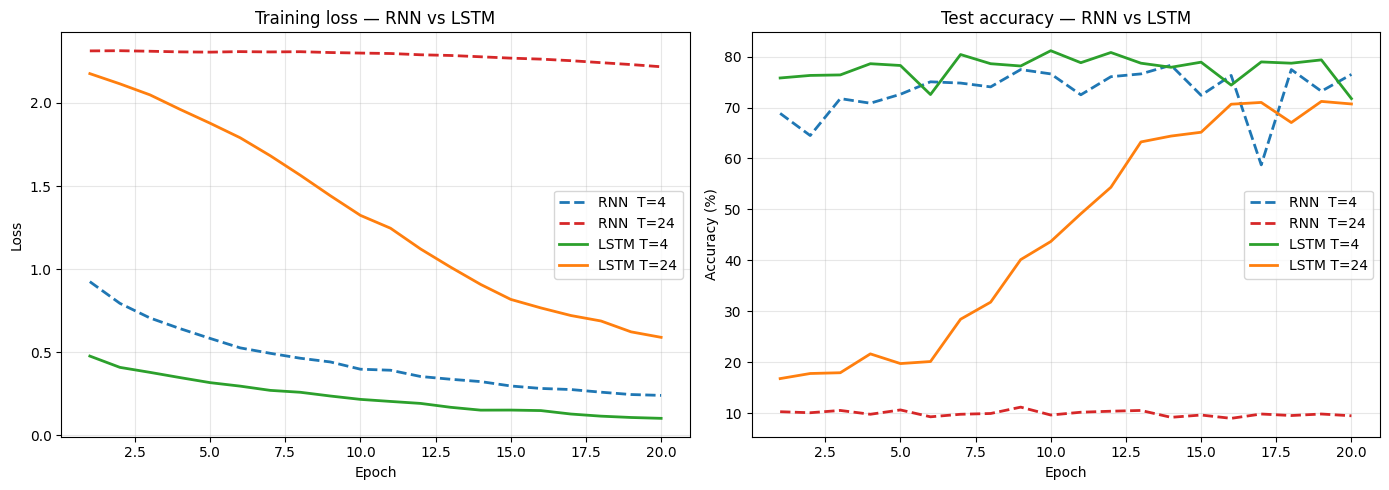

run           final loss   test acc
rnn-T4            0.2409     76.50%
rnn-T24           2.2181      9.50%
lstm-T4           0.1028     71.75%
lstm-T24          0.5902     70.70%


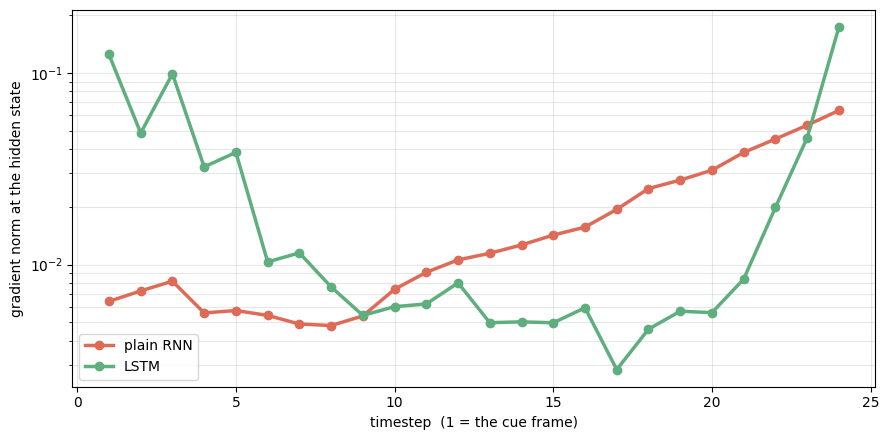

RNN  decay factor t=24 -> t=1: 9.88e+00
LSTM decay factor t=24 -> t=1: 1.39e+00


In [7]:
# =========================================================
# Train LSTM at T=4 and T=24 (reuses train_seq_2phase)
# =========================================================
for T_len in (4, 24):
    name = f"lstm-T{T_len}"
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    m = SeqModel("lstm")
    m.enc.load_state_dict(pretrained_enc_state)
    seq_results[name] = train_seq_2phase(
        m, T_len, epochs_frozen=4, epochs_ft=20, lr=1e-3, tag=name)
    trained_models[name] = m


# =========================================================
# Combined loss & accuracy — all four runs
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
styles = {
    "rnn-T4":   {"color": "#1f77b4", "ls": "--", "label": "RNN  T=4"},
    "rnn-T24":  {"color": "#d62728", "ls": "--", "label": "RNN  T=24"},
    "lstm-T4":  {"color": "#2ca02c", "ls": "-",  "label": "LSTM T=4"},
    "lstm-T24": {"color": "#ff7f0e", "ls": "-",  "label": "LSTM T=24"},
}
for name, cfg in styles.items():
    h = seq_results[name]
    ep = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], color=cfg["color"], ls=cfg["ls"], lw=2, label=cfg["label"])
    axes[1].plot(ep, [a * 100 for a in h["test_acc"]],
                 color=cfg["color"], ls=cfg["ls"], lw=2, label=cfg["label"])
axes[0].set_title("Training loss — RNN vs LSTM"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[1].set_title("Test accuracy — RNN vs LSTM"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")
for ax in axes: ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'run':<12}{'final loss':>12}{'test acc':>11}")
for k in ("rnn-T4", "rnn-T24", "lstm-T4", "lstm-T24"):
    h = seq_results[k]
    print(f"{k:<12}{h['train_loss'][-1]:>12.4f}{h['test_acc'][-1]*100:>10.2f}%")


# =========================================================
# Gradient at each timestep — RNN vs LSTM, both at T=24
# =========================================================
gn_lstm = timestep_grad_norms(trained_models["lstm-T24"], 24)
assert len(gn_lstm) == 24

plt.figure(figsize=(9, 4.5))
plt.semilogy(range(1, 25), gn_rnn,  "o-", lw=2.5, color="#DE6B58", label="plain RNN")
plt.semilogy(range(1, 25), gn_lstm, "o-", lw=2.5, color="#5FAE7E", label="LSTM")
plt.xlabel("timestep  (1 = the cue frame)")
plt.ylabel("gradient norm at the hidden state")
plt.grid(alpha=0.3, which="both"); plt.legend(); plt.tight_layout(); plt.show()

decay_rnn  = gn_rnn[-1]  / max(gn_rnn[0],  1e-30)
decay_lstm = gn_lstm[-1] / max(gn_lstm[0], 1e-30)
print(f"RNN  decay factor t=24 -> t=1: {decay_rnn:.2e}")
print(f"LSTM decay factor t=24 -> t=1: {decay_lstm:.2e}")